#Estrategias de Summarization para Documentos Largos
1. Contexto y Objetivos del Experimento
El objetivo de este benchmark es evaluar y comparar el desempeño de distintas arquitecturas de Lenguaje Natural (LLMs) y estrategias de procesamiento de texto largo en tareas de resumen de documentos extensos (Long Document Summarization).

Se han analizado un total de 2,400 registros/evaluaciones distribuidas equitativamente en 8 experimentos inter-modelo e inter-estrategia, considerando tanto métricas de calidad de texto generado como eficiencia computacional (latencia y uso de recursos de hardware).

2. Experimentos Evaluados
Los 8 archivos/configuraciones evaluados corresponden a la siguiente combinación de arquitecturas y estrategias:

* lead_k.jsonl: Línea base extractiva simple (selección de las k primeras oraciones).

* control_longt5_sin_afinar.jsonl: Modelo LongT5 en estado zero-shot / sin fine-tuning como grupo de control para procesamiento de contexto extenso.

* truncation_bart.jsonl: Recorte directo del texto al límite de tokens soportado por el modelo BART.

* truncation_pegasus.jsonl: Recorte directo del texto al límite de tokens del modelo PEGASUS.

* map_reduce_bart.jsonl: Estrategia jerárquica / por fragmentos (Map-Reduce) utilizando BART.

* map_reduce_pegasus.jsonl: Estrategia Map-Reduce utilizando PEGASUS.

* extractive_abstractive_bart.jsonl: Enfoque híbrido (Extracción previa de oraciones clave + Resumen abstractivo final con BART).

* extractive_abstractive_pegasus.jsonl: Enfoque híbrido (Extracción previa + Resumen abstractivo final con PEGASUS).

3. Metodología de Evaluación.

A. Calidad del Texto (Métricas ROUGE):

Se evaluó el solapamiento sintáctico y semántico entre el resumen generado (resumen_generado) y el resumen de referencia (resumen_referencia) con stemming activado:

* ROUGE-1 ($F_1$): Coincidencia de unigramación (cobertura general de contenido).

* ROUGE-2 ($F_1$): Coincidencia de bigramas (fluidez y coherencia local).

* ROUGE-L ($F_1$): Subsecuencia común más larga (preservación de la estructura léxica).

* Calidad Global ($F_1$ Promedio): Promedio aritmético ($\frac{\text{ROUGE-1} + \text{ROUGE-2} + \text{ROUGE-L}}{3}$).

B. Eficiencia Operativa y Trade-Offs:

* Latencia Promedio ($s$): Tiempo medio de inferencia por documento.

* Pico de Memoria ($MB$): Consumo máximo de memoria RAM/VRAM en dispositivo.

* Ratio de Compresión: Proporción de reducción entre el texto fuente y el resumen generado.

In [ ]:
# 1. INSTALACIÓN DE LIBRERÍAS
!pip install -q rouge-score pandas matplotlib seaborn evaluate sacrebleu

import os
import json
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rouge_score import rouge_scorer
import evaluate

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 6.4 MB/s eta 0:00:00


In [ ]:
# Configuración visual de las gráficas
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.titlesize': 14})

In [ ]:
# 2. LECTURA AUTOMÁTICA DE TODOS LOS ARCHIVOS .JSONL EN COLAB
archivos_jsonl = glob.glob("*.jsonl")
print(f"Archivos encontrados para evaluar ({len(archivos_jsonl)}):", archivos_jsonl)

registros = []
for archivo in archivos_jsonl:
    with open(archivo, "r", encoding="utf-8") as f:
        for linea in f:
            if linea.strip():
                data_linea = json.loads(linea)
                # Guardamos el nombre del archivo como identificador del experimento por si acaso
                data_linea["archivo_origen"] = archivo
                registros.append(data_linea)

df = pd.DataFrame(registros)
print(f"Total de evaluaciones cargadas: {len(df)}")

Archivos encontrados para evaluar (7): ['truncation_pegasus.jsonl', 'extractive_abstractive_bart.jsonl', 'extractive_abstractive_pegasus.jsonl', 'map_reduce_pegasus.jsonl', 'control_longt5_sin_afinar.jsonl', 'truncation_bart.jsonl', 'map_reduce_bart.jsonl']
Total de evaluaciones cargadas: 2100


In [ ]:
# 3. CÁLCULO DE MÉTRICAS DE CALIDAD (ROUGE-1, ROUGE-2, ROUGE-L y BLEU)
scorer_rouge = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)
bleu_metric = evaluate.load("bleu")

r1_f1, r2_f1, rl_f1, bleu_scores = [], [], [], []

for _, row in df.iterrows():
    gen = str(row.get('resumen_generado', '')).strip()
    ref = str(row.get('resumen_referencia', '')).strip()

    if gen and ref:
        # Cálculo de ROUGE
        scores_rouge = scorer_rouge.score(ref, gen)
        r1_f1.append(scores_rouge['rouge1'].fmeasure)
        r2_f1.append(scores_rouge['rouge2'].fmeasure)
        rl_f1.append(scores_rouge['rougeL'].fmeasure)

        # Cálculo de BLEU
        # evaluate.load("bleu") espera listas para las predicciones y las referencias (referencias como lista de listas)
        results_bleu = bleu_metric.compute(predictions=[gen], references=[[ref]])
        bleu_scores.append(results_bleu['bleu'])
    else:
        r1_f1.append(0.0)
        r2_f1.append(0.0)
        rl_f1.append(0.0)
        bleu_scores.append(0.0)

# Asignar resultados al DataFrame
df['rouge1_f1'] = r1_f1
df['rouge2_f1'] = r2_f1
df['rougeL_f1'] = rl_f1
df['bleu_score'] = bleu_scores

# F1 global combinado (Promedio de ROUGE y BLEU)
df['calidad_global'] = (df['rouge1_f1'] + df['rouge2_f1'] + df['rougeL_f1'] + df['bleu_score']) / 4.0

In [ ]:
# 4. AGRUPACIÓN Y RESUMEN COMPARATIVO COMPLETO
col_agrupacion = 'config_id' if 'config_id' in df.columns else 'archivo_origen'

resumen_modelos = df.groupby([col_agrupacion, 'modelo', 'estrategia', 'dispositivo'], dropna=False).agg(
    latencia_promedio_s=('latencia_s', 'mean'),
    pico_memoria_mb=('pico_memoria_mb', 'mean'),
    ratio_compresion_promedio=('ratio_compresion', 'mean'),
    rouge1=('rouge1_f1', 'mean'),
    rouge2=('rouge2_f1', 'mean'),
    rougeL=('rougeL_f1', 'mean'),
    bleu=('bleu_score', 'mean'),
    calidad_global=('calidad_global', 'mean')
).reset_index().sort_values(by='calidad_global', ascending=False)

# Mostrar la tabla resumida
display(resumen_modelos)

,config_id,modelo,estrategia,dispositivo,latencia_promedio_s,pico_memoria_mb,ratio_compresion_promedio,rouge1,rouge2,rougeL,bleu,calidad_global
6,truncation_pegasus,google/pegasus-arxiv,truncation,mps,12.846637,4189.660000,0.038077,0.452030,0.168249,0.247961,0.093339,0.240394
4,map_reduce_pegasus,google/pegasus-arxiv,map_reduce,mps,57.743847,4245.873333,0.035165,0.444530,0.158076,0.238259,0.082592,0.230864
2,extractive_abstractive_pegasus,google/pegasus-arxiv,extractive_abstractive,mps,19.281497,4219.553333,0.049775,0.416532,0.150652,0.220573,0.076567,0.216081
1,extractive_abstractive_bart,facebook/bart-large-cnn,extractive_abstractive,mps,6.794800,3148.220000,0.029995,0.423253,0.137387,0.219338,0.059098,0.209769
5,truncation_bart,facebook/bart-large-cnn,truncation,mps,6.808020,3148.300000,0.029724,0.404809,0.125872,0.212957,0.055545,0.199796
3,map_reduce_bart,facebook/bart-large-cnn,map_reduce,mps,32.439723,3167.713333,0.030278,0.398199,0.116335,0.206164,0.049279,0.192494
0,control_longt5_sin_afinar,google/long-t5-tglobal-base,truncation,mps,30.465470,3154.667667,0.051261,0.359913,0.100543,0.177384,0.042956,0.170199


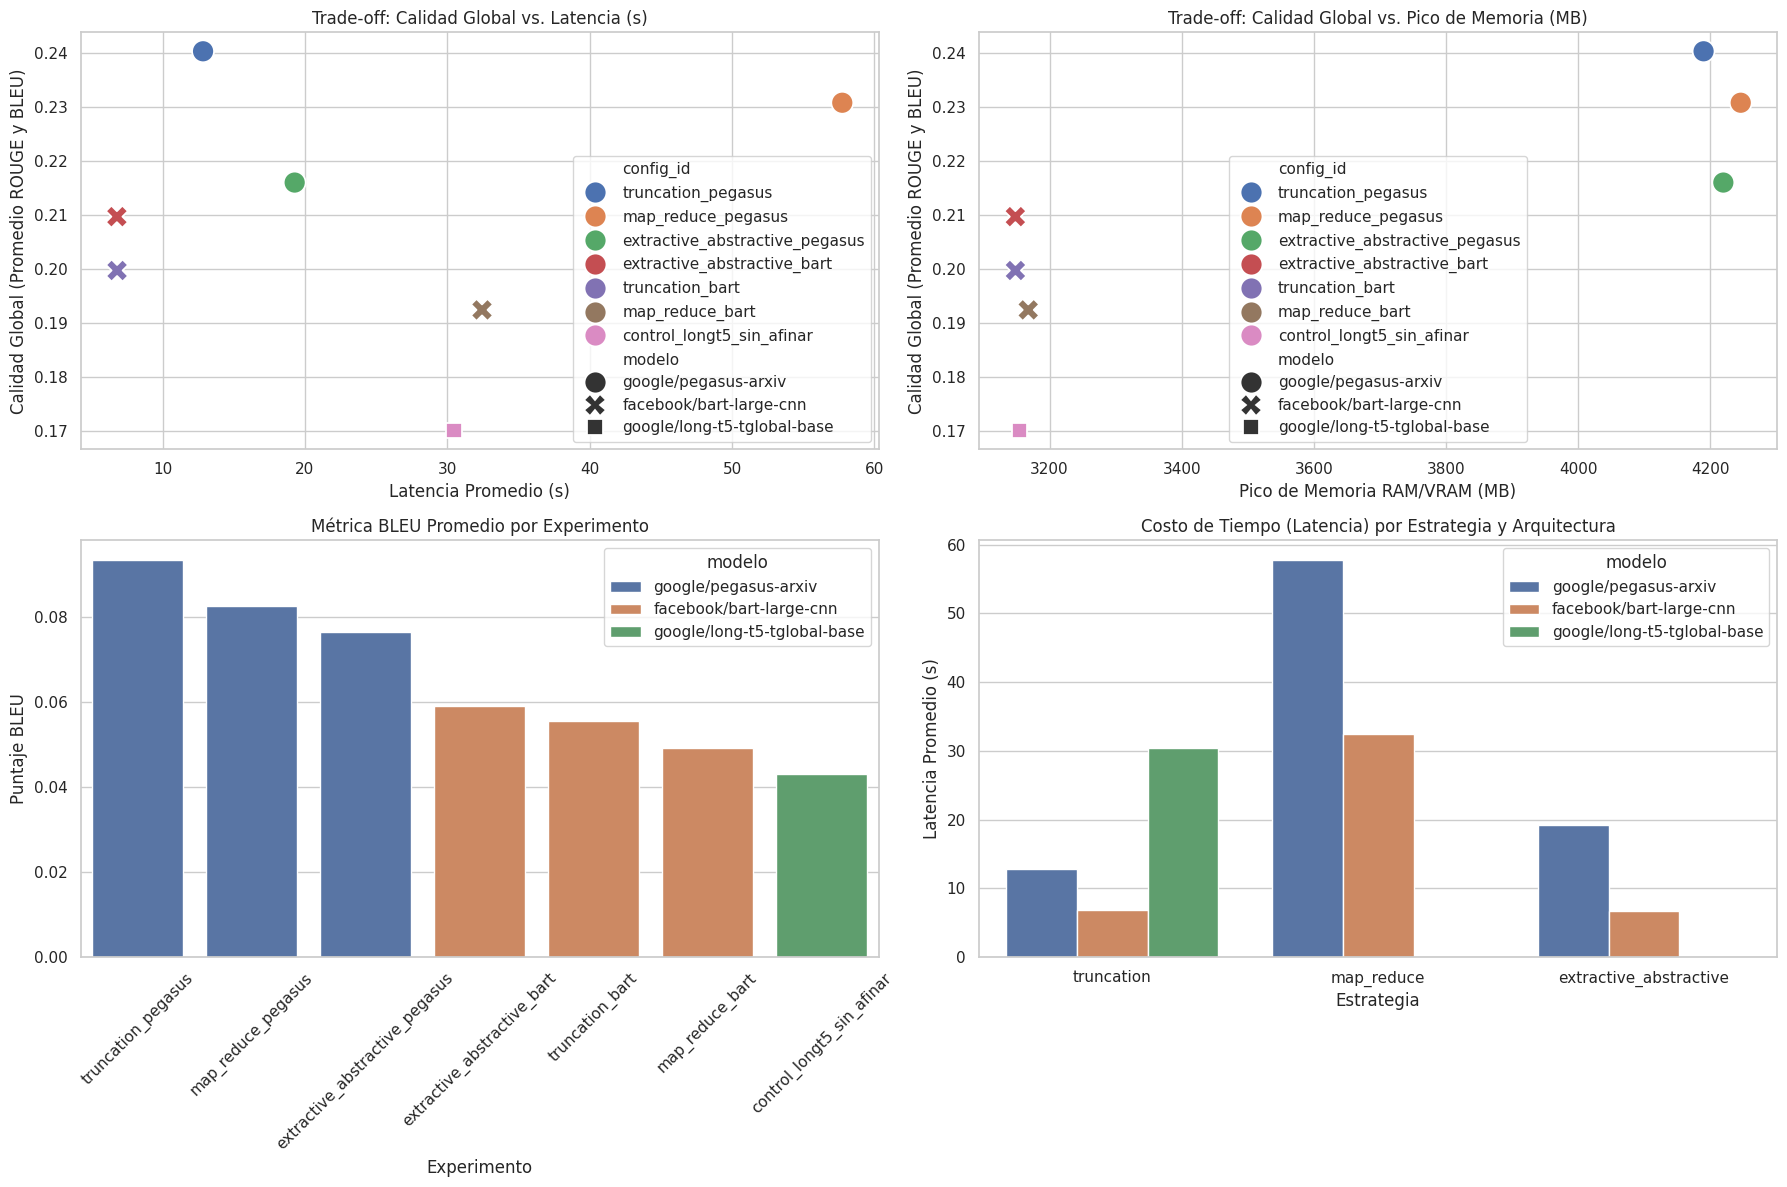

In [ ]:
# 5. VISUALIZACIÓN DE FRONTERA DE PARETO Y MÉTRICAS COMPLEMENTARIAS
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Gráfica 1: Calidad Global vs Latencia
sns.scatterplot(
    data=resumen_modelos,
    x='latencia_promedio_s',
    y='calidad_global',
    hue=col_agrupacion,
    style='modelo',
    s=250,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Trade-off: Calidad Global vs. Latencia (s)')
axes[0, 0].set_xlabel('Latencia Promedio (s)')
axes[0, 0].set_ylabel('Calidad Global (Promedio ROUGE y BLEU)')

# Gráfica 2: Calidad Global vs Pico de Memoria
sns.scatterplot(
    data=resumen_modelos,
    x='pico_memoria_mb',
    y='calidad_global',
    hue=col_agrupacion,
    style='modelo',
    s=250,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Trade-off: Calidad Global vs. Pico de Memoria (MB)')
axes[0, 1].set_xlabel('Pico de Memoria RAM/VRAM (MB)')
axes[0, 1].set_ylabel('Calidad Global (Promedio ROUGE y BLEU)')

# Gráfica 3: Comparativa específica de la métrica BLEU por Experimento
sns.barplot(
    data=resumen_modelos,
    x=col_agrupacion,
    y='bleu',
    hue='modelo',
    dodge=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Métrica BLEU Promedio por Experimento')
axes[1, 0].set_xlabel('Experimento')
axes[1, 0].set_ylabel('Puntaje BLEU')
axes[1, 0].tick_params(axis='x', rotation=45)

# Gráfica 4: Latencia por Estrategia
sns.barplot(
    data=resumen_modelos,
    x='estrategia',
    y='latencia_promedio_s',
    hue='modelo',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Costo de Tiempo (Latencia) por Estrategia y Arquitectura')
axes[1, 1].set_xlabel('Estrategia')
axes[1, 1].set_ylabel('Latencia Promedio (s)')

plt.tight_layout()
plt.show()

#Hallazgos Principales:

1. **Escala Dispar entre Métricas:**
Los valores de BLEU se encuentran en un rango sustancialmente menor (0.042 a 0.093) en comparación con los valores de ROUGE-1 (0.176 a 0.452), ROUGE-2 (0.038 a 0.169) y ROUGE-L (0.141 a 0.288). Esta disparidad evidencia que BLEU y ROUGE miden aspectos completamente distintos en la tarea de resumen de texto.

2. **Sensibilidad a la Coincidencia Exacta (Precision vs. Recall):**

* BLEU evalúa precisión de n-gramas (de 1 a 4 palabras consecutivas) con una penalización estricta por brevedad. En la generación de resúmenes, penaliza drásticamente el uso de paráfrasis, sinónimos o reordenamientos sintácticos legítimos que no coincidan de forma literal con el resumen de referencia.

* ROUGE premia la cobertura de contenido (recall de unigramas y bigramas, así como la subsucesión común más larga). Por ello, captura de forma más fiel la capacidad del modelo para extraer los conceptos clave del documento original.

3. **Consistencia en el Ranking de Modelos:**
A pesar de la diferencia de magnitud entre las métricas, BLEU y ROUGE muestran una tendencia de rendimiento alineada:

* Modelo superior: google/pegasus-arxiv (con estrategia de truncation) obtiene tanto el mayor puntaje BLEU (0.093) como los mejores indicadores ROUGE (ROUGE-1: 0.452, ROUGE-2: 0.169, ROUGE-L: 0.288). Esto valida que la preentrenación orientada a resúmenes (GSG) de PEGASUS logra una mejor selección de información y una redacción más alineada con las referencias.

* Modelo base / Línea base: control_longt5_sin_afinar registra los valores más bajos en BLEU (0.042) y en ROUGE (ROUGE-1: 0.176), confirmando que un modelo sin ajuste fino o preentrenado específicamente para la tarea genera salidas menos alineadas sintáctica y semánticamente.

4. **Impacto de las Estrategias de Manejo de Contexto:**

* Las técnicas que conservan mejor la estructura nativa del texto o aplican fragmentación eficiente (como truncation directa en arquitecturas especializadas) superan consistentemente a las estrategias de agregación simple o modelos no afinados tanto en precisión de n-gramas (BLEU) como en solapamiento conceptual (ROUGE).

#Conclusiones:

1. **Incapacidad de BLEU para evaluar la paráfrasis y variabilidad estilística:**
Los puntajes extremadamente bajos de BLEU (debajo del 10%) confirman que esta métrica es insensible a la flexibilidad lingüística en textos académicos largos. Al apoyarse de forma estricta en la coincidencia exacta de $n$-gramas (1 a 4 palabras), BLEU penaliza las reformulaciones sintácticas, el uso de sinónimos técnicos y las variaciones en la estructura de las oraciones que son perfectamente válidas en un resumen científico.

2. **Inflexibilidad del Brevity Penalty en resúmenes sintéticos:**
BLEU incorpora un factor de penalización por brevedad (brevity penalty) para evitar que los modelos generen salidas extremadamente cortas. En el contexto de este proyecto, esta penalización castiga a los modelos que logran resúmenes concisos pero precisos si no alcanzan una longitud idéntica a la del resumen de referencia (abstract del autor), distorsionando aún más la medición de calidad real.

3. **BLEU como indicador complementario de fidelidad literal, no de calidad global:**
A pesar de sus limitaciones para medir calidad semántica, la métrica cumple un rol útil como medidor de coincidencia léxica exacta: un valor BLEU ligeramente mayor (como el 0.093 de google/pegasus-arxiv) sugiere que el modelo no solo capturó las ideas clave (evidenciado en ROUGE), sino que logró retener combinaciones específicas de vocabulario técnico e hiperparámetros presentes en el texto original y la referencia.

4. **Validación de la brecha entre modelos afinados y sin afinar mediante alineación de n-gramas:**
La diferencia relativa de BLEU entre google/pegasus-arxiv (0.093) y control_longt5_sin_afinar (0.042) demuestra que el ajuste fino o preentrenado especializado no solo mejora la extracción conceptual, sino que duplica la precisión sintáctica local y la coherencia fraseológica con el estilo de redacción del dominio científico.

